In [1]:
import pandas as pd 

df_products = pd.read_csv('amz_uk_price_prediction_dataset.csv')
df_products

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [7]:
#PART 1 - 1) Crosstab Analysis

category_cross_isBestSeller = pd.crosstab(df_products['category'], df_products['isBestSeller'])
category_cross_isBestSeller

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [8]:
bestSellersOnly = category_cross_isBestSeller[category_cross_isBestSeller[True] > category_cross_isBestSeller[False]]
bestSellersOnly

#There are no categories where being a best-seller prevails

isBestSeller,False,True
category,,


In [ ]:
#PART 1 - 2) Statistical Tests
#Chi-square

from scipy.stats import chi2_contingency

contingency_table = pd.crosstab(df_products['category'], df_products['isBestSeller'])

chi2, p, dof, expected = chi2_contingency(contingency_table)

print(f"P-value: {p:.4f}")

P-value: 0.0000


In [ ]:
# Cramér's V

import numpy as np

n = contingency_table.sum().sum()
min_dim = min(contingency_table.shape) - 1

cramers_v = np.sqrt(chi2 / (n * min_dim))

print("Cramér's V:", cramers_v)

Cramér's V: 0.1222829439760564


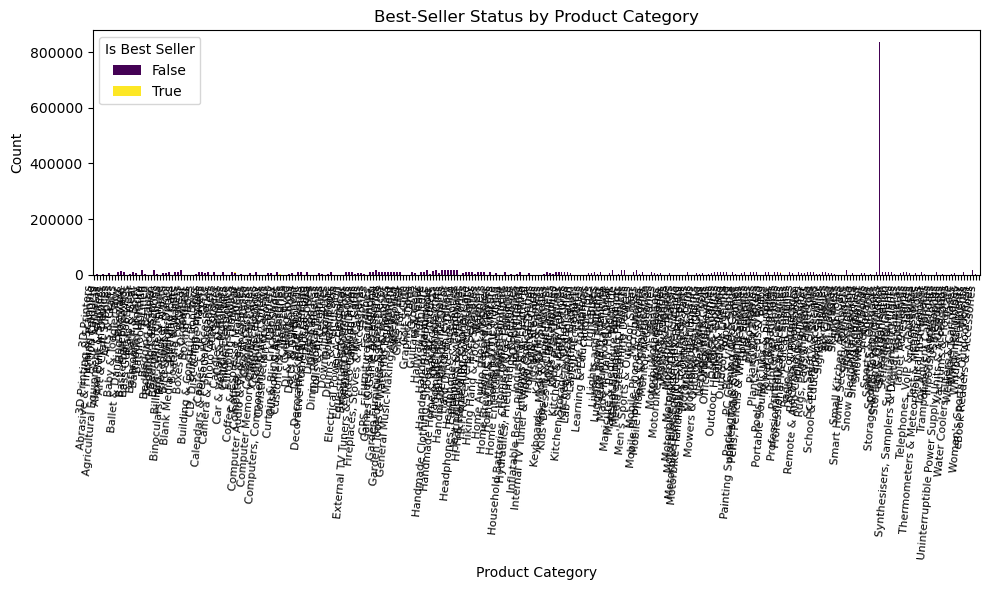

In [6]:
#PART 1 - 3) Visualizations

import pandas as pd
import matplotlib.pyplot as plt

contingency_table = pd.crosstab(df_products['category'], df_products['isBestSeller'])

contingency_table.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='viridis')

plt.title('Best-Seller Status by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Count')
plt.legend(title='Is Best Seller')
plt.xticks(rotation=85, ha='right', fontsize = 8)
plt.tight_layout()
plt.show()

In [ ]:
# PART 2

Q1 = df_products['price'].quantile(0.25)
Q3 = df_products['price'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_no_outliers = df_products[(df_products['price'] >= lower_bound) & (df_products['price'] <= upper_bound)]

print(f"Removed {len(df_products) - len(df_no_outliers)} outliers from the dataset.")

Removed 327688 outliers from the dataset.


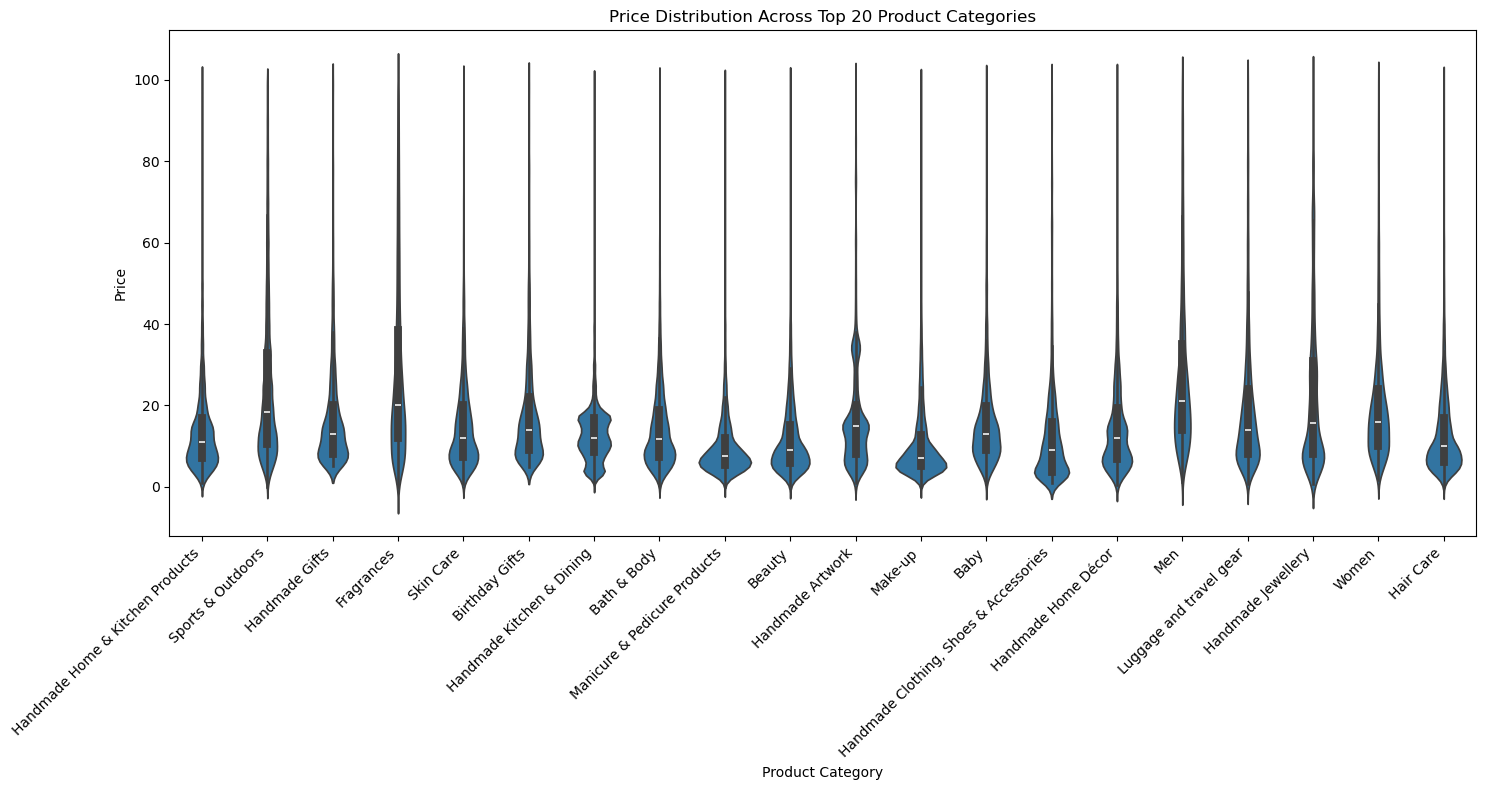

In [ ]:
#   1) Violin plots

import seaborn as sns

top_categories = df_no_outliers['category'].value_counts().nlargest(20).index

df_top20 = df_no_outliers[df_no_outliers['category'].isin(top_categories)]

plt.figure(figsize=(15, 8))
sns.violinplot(x='category', y='price', data=df_top20, inner='box')

plt.title('Price Distribution Across Top 20 Product Categories')
plt.xlabel('Product Category')
plt.ylabel('Price')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [9]:
median_prices = df_no_outliers.groupby('category')['price'].median()

highest_median_category = median_prices.idxmax()
highest_median_price = median_prices.max()

print(f"The category with the highest median price is '{highest_median_category}' with a median price of {highest_median_price}.")

The category with the highest median price is 'Desktop PCs' with a median price of 74.0.


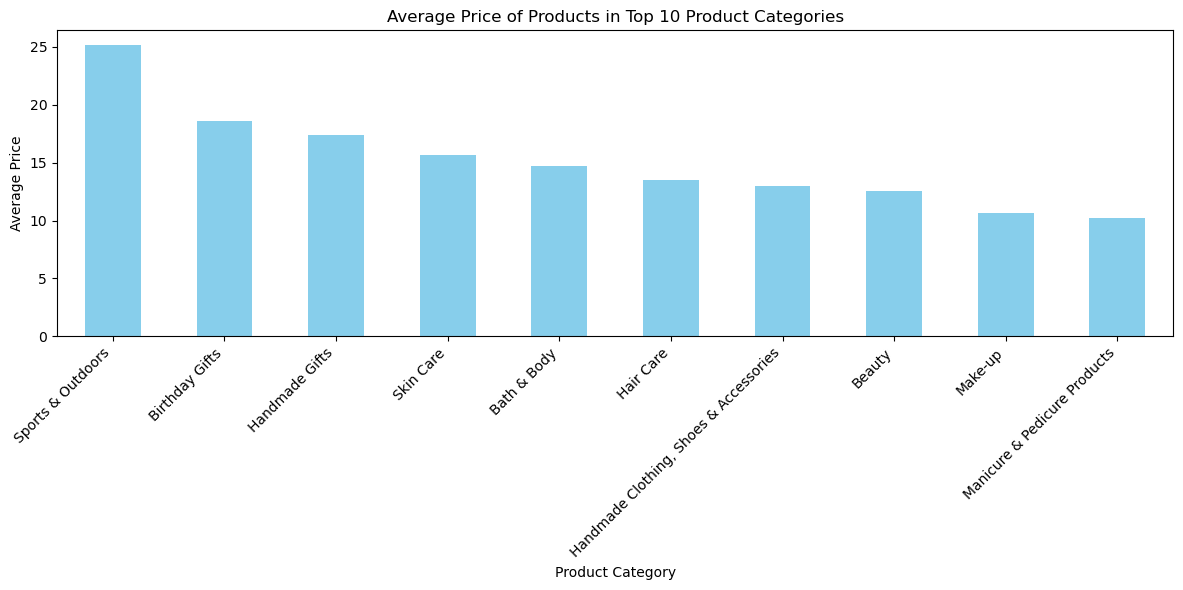

In [10]:
#   2) Bar charts

top_10_categories = df_no_outliers['category'].value_counts().nlargest(10).index

df_top10 = df_no_outliers[df_no_outliers['category'].isin(top_10_categories)]

avg_prices_top10 = df_top10.groupby('category')['price'].mean().sort_values(ascending=False)

plt.figure(figsize=(12, 6))
avg_prices_top10.plot(kind='bar', color='skyblue')

plt.title('Average Price of Products in Top 10 Product Categories')
plt.xlabel('Product Category')
plt.ylabel('Average Price')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [11]:
avg_prices_all = df_no_outliers.groupby('category')['price'].mean()

highest_avg_category = avg_prices_all.idxmax()
highest_avg_price = avg_prices_all.max()

print(f"The category with the highest average price is '{highest_avg_category}' with an average price of {highest_avg_price}.")

The category with the highest average price is 'Motherboards' with an average price of 68.77243243243242.


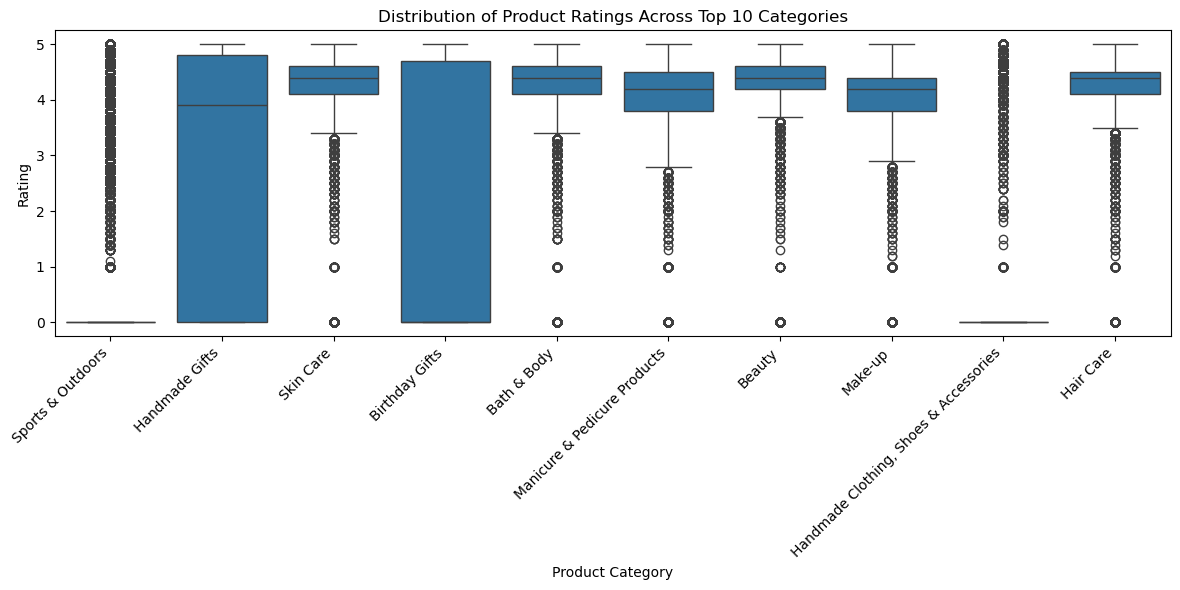

In [13]:
#   3) Box plots

top_10_categories = df_no_outliers['category'].value_counts().nlargest(10).index

df_top10 = df_no_outliers[df_no_outliers['category'].isin(top_10_categories)]

plt.figure(figsize=(12, 6))
sns.boxplot(x='category', y='stars', data=df_top10)

plt.title('Distribution of Product Ratings Across Top 10 Categories')
plt.xlabel('Product Category')
plt.ylabel('Rating')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [14]:
median_ratings = df_no_outliers.groupby('category')['stars'].median()

highest_median_rating_category = median_ratings.idxmax()
highest_median_rating = median_ratings.max()

print(f"The category with the highest median rating is '{highest_median_rating_category}' with a median rating of {highest_median_rating}.")

The category with the highest median rating is 'Computer Memory' with a median rating of 4.7.


In [15]:
# PART 3 - 1) Correlation coefficients

from scipy.stats import pearsonr

df_corr = df_no_outliers[['price', 'stars']].dropna()

corr_coef, p_value = pearsonr(df_corr['price'], df_corr['stars'])

print(f"Pearson correlation coefficient: {corr_coef}")
print(f"P-value: {p_value}")

Pearson correlation coefficient: -0.0776729987818133
P-value: 0.0


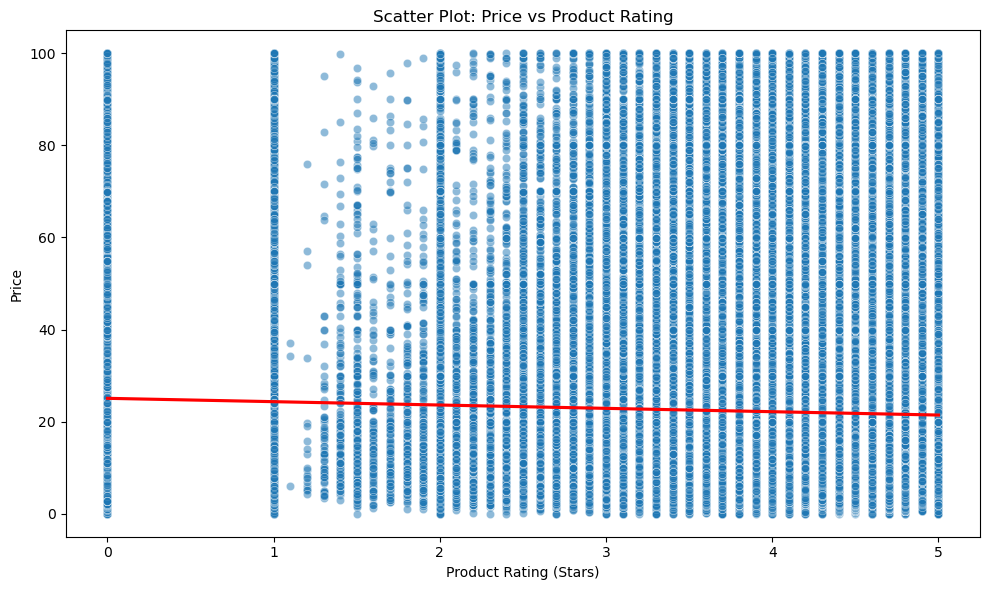

In [16]:
#   2) Visalizations

df_corr = df_no_outliers[['price', 'stars']].dropna()

plt.figure(figsize=(10, 6))
sns.scatterplot(x='stars', y='price', data=df_corr, alpha=0.5)
sns.regplot(x='stars', y='price', data=df_corr, scatter=False, color='red')

plt.title('Scatter Plot: Price vs Product Rating')
plt.xlabel('Product Rating (Stars)')
plt.ylabel('Price')
plt.tight_layout()
plt.show()

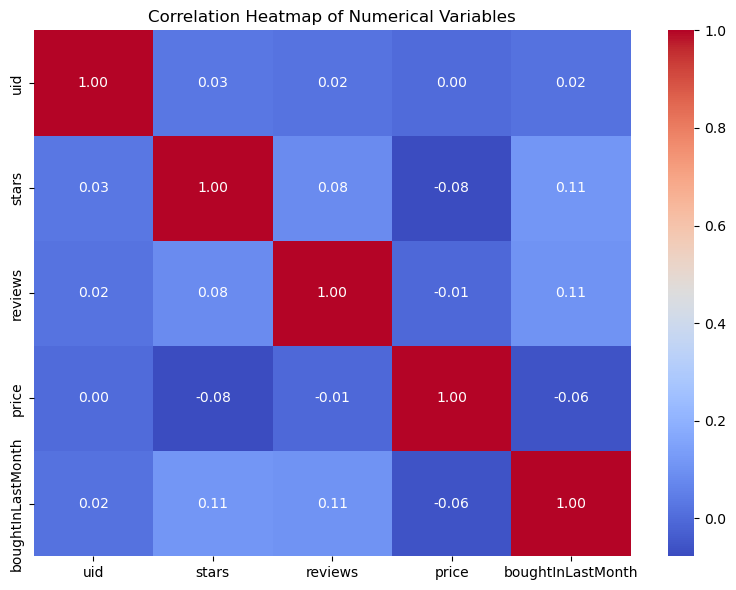

In [17]:
numeric_cols = df_no_outliers.select_dtypes(include=np.number)

corr_matrix = numeric_cols.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Numerical Variables')
plt.tight_layout()
plt.show()

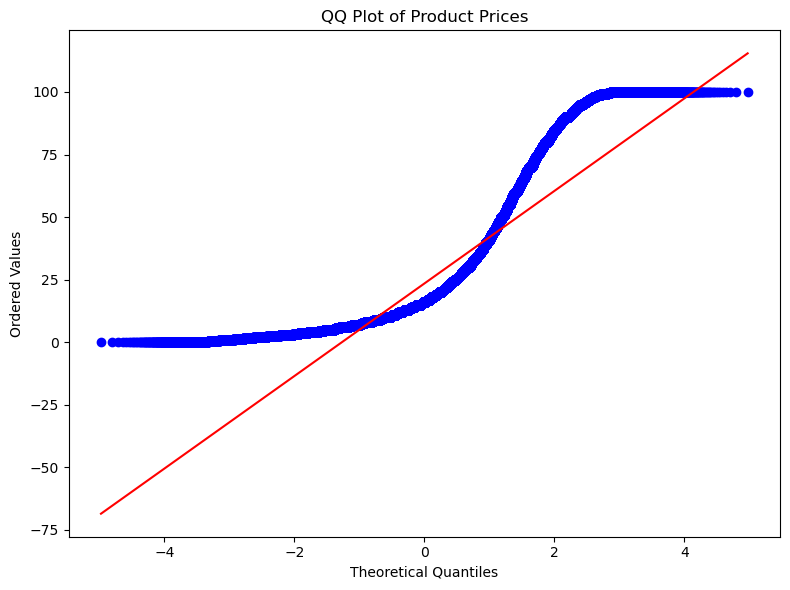

In [18]:
import scipy.stats as stats

plt.figure(figsize=(8, 6))
stats.probplot(df_no_outliers['price'], dist="norm", plot=plt)
plt.title('QQ Plot of Product Prices')
plt.xlabel('Theoretical Quantiles')
plt.ylabel('Ordered Values')
plt.tight_layout()
plt.show()